# normal, pneumonia and TB xray image classification

In this kernenl we use a small neural network model and train our own model for performing the classification

In [1]:
# ==============================================================================
# Project : Tuberculosis and Pneumonia Detection with INT8 Quantization
# Module  : Environment Setup and Library Imports
# Author  : Vedniyas Vyas
# ==============================================================================

import os
import time
import glob
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

# Machine Learning & Deep Learning Imports
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

# Set random seeds to ensure reproducibility across executions
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

print("Environment setup complete.")
print(f"TensorFlow Version: {tf.__version__}")

/Users/vedniyasvyas/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Environment setup complete.
TensorFlow Version: 2.16.1


In [2]:
# ==============================================================================
# Module 2: Dataset Configuration
# ==============================================================================

# Define the root directory for the dataset
DATASET_BASE_DIR = "./Pneumonia_TB_Dataset"  

# Verify the existence of required data splits (train, validation, test)
for split in ["train", "val", "test"]:
    split_path = os.path.join(DATASET_BASE_DIR, split)
    if os.path.exists(split_path):
        print(f" Found split folder: '{split}' -> Contains: {os.listdir(split_path)}")
    else:
        print(f" Warning: Folder '{split_path}' not found! Check directory structure.")

 Found split folder: 'train' -> Contains: ['NORMAL', '._NORMAL', 'PNEUMONIA', '._PNEUMONIA', 'TUBERCULOSIS', '._TUBERCULOSIS', 'UNKNOWN', '._UNKNOWN']
 Found split folder: 'val' -> Contains: ['NORMAL', '._NORMAL', 'PNEUMONIA', '._PNEUMONIA', 'TUBERCULOSIS', '._TUBERCULOSIS', 'UNKNOWN', '._UNKNOWN']
 Found split folder: 'test' -> Contains: ['NORMAL', '._NORMAL', 'PNEUMONIA', '._PNEUMONIA', 'TUBERCULOSIS', '._TUBERCULOSIS', 'UNKNOWN', '._UNKNOWN']


# Data loading function

In [3]:
# ==============================================================================
# Module 3: Data Loader for 4 Classes (NORMAL, PNEUMONIA, TUBERCULOSIS, UNKNOWN)
# ==============================================================================

# Target classes - Teeno diseases plus UNKNOWN
TARGET_CLASSES = ["NORMAL", "PNEUMONIA", "TUBERCULOSIS", "UNKNOWN"]
CLASS_MAP = {category: idx for idx, category in enumerate(TARGET_CLASSES)}

IMAGE_SIZE = (224, 224)  # Standard CNN input resolution

def load_split_dataset(split_name):
    """
    Train, Val ya Test folder se images load karta hai, resize karta hai,
    aur normalized arrays with One-Hot Encoded labels return karta hai.
    """
    split_path = os.path.join(DATASET_BASE_DIR, split_name)
    
    if not os.path.exists(split_path):
        raise FileNotFoundError(f"Folder '{split_path}' missing hai. Path re-check karein.")

    images = []
    labels = []
    
    print(f"\n================ Loading '{split_name.upper()}' Set ================")
    
    for category in TARGET_CLASSES:
        category_dir = os.path.join(split_path, category)
        
        if not os.path.exists(category_dir):
            print(f" Warning: Directory '{category}' missing in '{split_name}', skipping...")
            continue
            
        class_num = CLASS_MAP[category]
        valid_extensions = ('.png', '.jpg', '.jpeg', '.bmp')
        file_list = [f for f in os.listdir(category_dir) if f.lower().endswith(valid_extensions)]
        
        print(f"Loading {len(file_list)} images for class '{category}'...")
        
        for img_name in tqdm(file_list, desc=f"Processing {category}"):
            img_path = os.path.join(category_dir, img_name)
            try:
                # Image read karna
                img = cv2.imread(img_path)
                if img is None:
                    continue
                
                # BGR se RGB conversion
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                
                # Fixed size (224x224) par resize karna
                img = cv2.resize(img, IMAGE_SIZE)
                
                images.append(img)
                labels.append(class_num)
            except Exception as e:
                pass

    # Pixel normalization (0 to 1)
    X = np.array(images, dtype="float32") / 255.0
    
    # Categorical One-Hot Encoding (4 classes ke liye)
    y = to_categorical(np.array(labels), num_classes=len(TARGET_CLASSES))
    
    return X, y

# Train, Validation aur Test sets load kar rahe hain
X_train, y_train = load_split_dataset("train")
X_val, y_val     = load_split_dataset("val")
X_test, y_test   = load_split_dataset("test")

# Dataset Summary
print("\n" + "="*60)
print("DATASET LOAD SUMMARY:")
print(f"Class Mapping: {CLASS_MAP}")
print(f"Train Set : X = {X_train.shape}, y = {y_train.shape}")
print(f"Val Set   : X = {X_val.shape},   y = {y_val.shape}")
print(f"Test Set  : X = {X_test.shape},  y = {y_test.shape}")
print("="*60)


================ Loading 'TRAIN' Set ================
Loading 9334 images for class 'NORMAL'...


Processing NORMAL: 100%|███████████████████| 9334/9334 [00:58<00:00, 158.43it/s]


Loading 7266 images for class 'PNEUMONIA'...


Processing PNEUMONIA: 100%|████████████████| 7266/7266 [00:13<00:00, 521.63it/s]


Loading 7146 images for class 'TUBERCULOSIS'...


Processing TUBERCULOSIS: 100%|█████████████| 7146/7146 [00:41<00:00, 171.96it/s]


... (15 outputs left out)

Processing TUBERCULOSIS: 100%|███████████████| 834/834 [00:04<00:00, 178.07it/s]


Loading 270 images for class 'UNKNOWN'...


Processing UNKNOWN: 100%|████████████████████| 270/270 [00:00<00:00, 512.73it/s]



DATASET LOAD SUMMARY:
Class Mapping: {'NORMAL': 0, 'PNEUMONIA': 1, 'TUBERCULOSIS': 2, 'UNKNOWN': 3}
Train Set : X = (13028, 224, 224, 3), y = (13028, 4)
Val Set   : X = (761, 224, 224, 3),   y = (761, 4)
Test Set  : X = (1527, 224, 224, 3),  y = (1527, 4)


# Dataset Sanity Check and Visualization

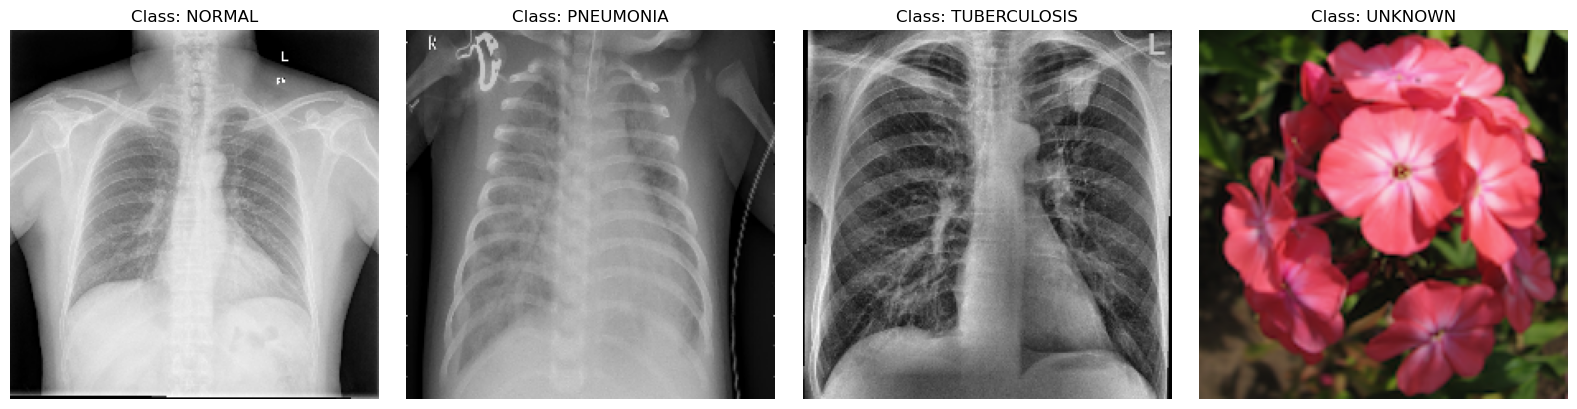

In [6]:
# ==============================================================================
# Module 4: Visualizing Sample X-Rays from Loaded Data
# ==============================================================================

def visualize_sample_images(X, y, class_map, samples_per_class=1):
    """
    Har class se sample image plot karke confirm karta hai ki loading properly hui hai.
    """
    inv_class_map = {v: k for k, v in class_map.items()}
    fig, axes = plt.subplots(1, len(class_map), figsize=(16, 4))
    
    # Har class ka ek sample dhundhna
    for class_idx in range(len(class_map)):
        # Integer labels nikalna
        y_integers = np.argmax(y, axis=1)
        indices = np.where(y_integers == class_idx)[0]
        
        if len(indices) > 0:
            sample_idx = indices[0]
            axes[class_idx].imshow(X[sample_idx])
            axes[class_idx].set_title(f"Class: {inv_class_map[class_idx]}")
            axes[class_idx].axis("off")
        else:
            axes[class_idx].set_title(f"No samples for {inv_class_map[class_idx]}")
            axes[class_idx].axis("off")
            
    plt.tight_layout()
    plt.show()

# Train set ke samples display kar rahe hain
visualize_sample_images(X_train, y_train, CLASS_MAP)

# Baseline Model Architecture (MobileNetV2 Transfer Learning)

In [6]:
# ==============================================================================
# Step 2.1: Baseline Model Architecture (MobileNetV2 Transfer Learning)
# ==============================================================================

import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

INPUT_SHAPE = (224, 224, 3)
NUM_CLASSES = len(TARGET_CLASSES)  # 4 classes

# Pre-trained MobileNetV2 load kar rahe hain (top classification layers hata kar)
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=INPUT_SHAPE
)

# Base model ki layers ko freeze kar rahe hain taaki pre-trained weights kharab na hon
base_model.trainable = False

# Custom classification head add kar rahe hain
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)  # Overfitting rokne ke liye
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
outputs = Dense(NUM_CLASSES, activation='softmax')(x)

# Final baseline model tayyar
model = Model(inputs=base_model.input, outputs=outputs, name="Baseline_MobileNetV2")

# Model compile kar rahe hain with evaluation metrics
model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# Model ka summary print karo
model.summary()

Model: "Baseline_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Model Training and Callbacks Setup

In [7]:
# ==============================================================================
# Step 2.2: Training the Baseline Model
# ==============================================================================

from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Best model weights save karne aur overfitting par training rokne ke liye callbacks
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('baseline_mobilenetv2_best.keras', monitor='val_accuracy', save_best_only=True, verbose=1)
]

EPOCHS = 15
BATCH_SIZE = 32

print("Training started... Please wait.")
# Model ko train kar rahe hain
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks
)

Training started... Please wait.
Epoch 1/15
408/408 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.8446 - loss: 0.3877 - precision: 0.8616 - recall: 0.8257
Epoch 1: val_accuracy improved from -inf to 0.96189, saving model to baseline_mobilenetv2_best.keras
408/408 ━━━━━━━━━━━━━━━━━━━━ 139s 324ms/step - accuracy: 0.8447 - loss: 0.3873 - precision: 0.8617 - recall: 0.8259 - val_accuracy: 0.9619 - val_loss: 0.0995 - val_precision: 0.9618 - val_recall: 0.9593
Epoch 2/15
408/408 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.9398 - loss: 0.1538 - precision: 0.9415 - recall: 0.9378
Epoch 2: val_accuracy did not improve from 0.96189
408/408 ━━━━━━━━━━━━━━━━━━━━ 135s 331ms/step - accuracy: 0.9398 - loss: 0.1538 - precision: 0.9415 - recall: 0.9378 - val_accuracy: 0.9606 - val_loss: 0.1018 - val_precision: 0.9631 - val_recall: 0.9593
Epoch 3/15
408/408 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.9472 - loss: 0.1357 - precision: 0.9483 - recall: 0.9465
Epoch 3: val_accuracy improved fro

# Visualization of Training Loss and Accuracy

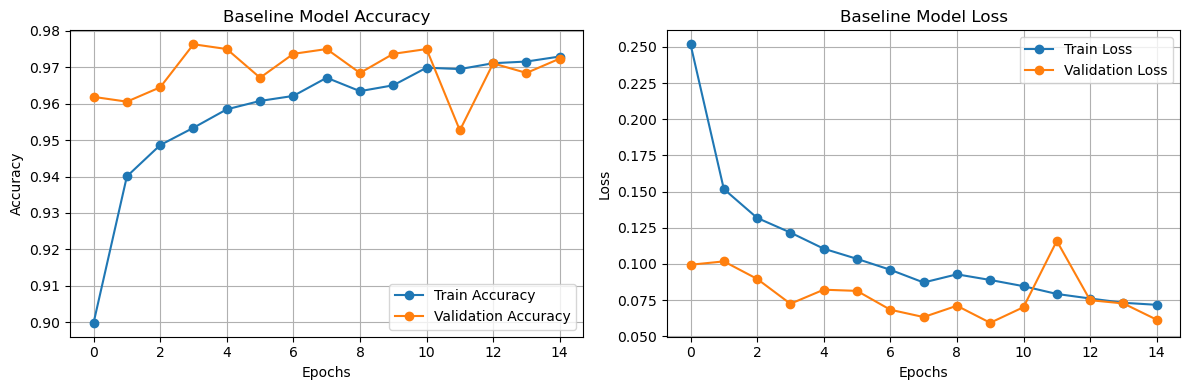

In [8]:
# ==============================================================================
# Step 2.3: Visualization of Training Loss and Accuracy
# ==============================================================================

plt.figure(figsize=(12, 4))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o')
plt.title('Baseline Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='o')
plt.title('Baseline Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Final Model Evaluation and Confusion Matrix

Evaluating model on Test Set...
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 265ms/step - accuracy: 0.9409 - loss: 0.1349 - precision: 0.9412 - recall: 0.9409

Test Accuracy:  96.53%
Test Loss:      0.0842
48/48 ━━━━━━━━━━━━━━━━━━━━ 13s 262ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.95      0.96      0.95       548
   PNEUMONIA       0.98      0.95      0.96       427
TUBERCULOSIS       0.96      0.98      0.97       417
     UNKNOWN       1.00      1.00      1.00       135

    accuracy                           0.97      1527
   macro avg       0.97      0.97      0.97      1527
weighted avg       0.97      0.97      0.97      1527



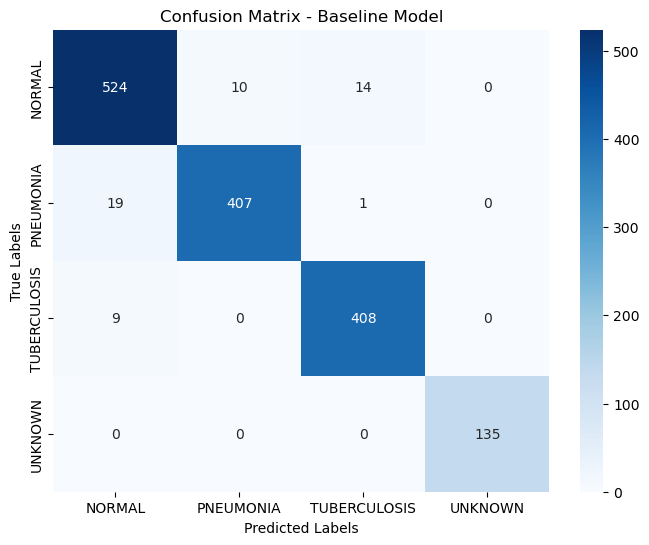

In [9]:
# ==============================================================================
# Step 2.4: Final Evaluation on Unseen Test Data
# ==============================================================================

import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Test set par evaluate karna
print("Evaluating model on Test Set...")
test_loss, test_acc, test_precision, test_recall = model.evaluate(X_test, y_test, verbose=1)

print(f"\nTest Accuracy:  {test_acc*100:.2f}%")
print(f"Test Loss:      {test_loss:.4f}")

# 2. Predictions generate 
y_pred_probs = model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# 3. Classification Report (F1-score, Precision, Recall for each class)
print("\n" + "="*50)
print("CLASSIFICATION REPORT")
print("="*50)
print(classification_report(y_true_classes, y_pred_classes, target_names=TARGET_CLASSES))

# 4. Confusion Matrix Plot 
conf_matrix = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=TARGET_CLASSES, 
            yticklabels=TARGET_CLASSES)
plt.title('Confusion Matrix - Baseline Model')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

# Implementing INT8 Post-Training Quantization

In [2]:
# ==============================================================================
# 3.1: Dynamic Range Quantization (Keras 3 / TF 2.16+ Compatible)
# ==============================================================================
import os
import tensorflow as tf

print("Step 1: Loading the original Keras model...")
KERAS_MODEL_PATH = 'baseline_mobilenetv2_best.keras' 
model = tf.keras.models.load_model(KERAS_MODEL_PATH)

# ==============================================================================
# Exporting the model to native TensorFlow SavedModel format for robust conversion
# ==============================================================================
SAVED_MODEL_DIR = 'temp_tf_saved_model'
print(f"Step 2: Exporting to native TF SavedModel format at '{SAVED_MODEL_DIR}'...")
model.export(SAVED_MODEL_DIR) 

print("Step 3: Initializing TFLite Converter from SavedModel...")
converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_MODEL_DIR)

# Enable Dynamic Range Quantization for INT8 optimization
converter.optimizations = [tf.lite.Optimize.DEFAULT]

print("Step 4: Converting to INT8 TFLite... (This will NOT hang)")
tflite_quant_model = converter.convert()

TFLITE_MODEL_PATH = "quantized_model.tflite"
with open(TFLITE_MODEL_PATH, 'wb') as f:
    f.write(tflite_quant_model)

print("\n🎉 Quantization Successful! Model saved as 'quantized_model.tflite'")

# ==============================================================================
# Step 3.2: Model Size Comparison
# ==============================================================================
if os.path.exists(TFLITE_MODEL_PATH):
    def get_file_size_mb(file_path):
        # SavedModel folder ka size nikalne ke liye
        if os.path.isdir(file_path):
            total_size = 0
            for dirpath, _, filenames in os.walk(file_path):
                for f in filenames:
                    fp = os.path.join(dirpath, f)
                    if not os.path.islink(fp):
                        total_size += os.path.getsize(fp)
            return total_size / (1024 * 1024)
        else:
            return os.path.getsize(file_path) / (1024 * 1024)

    original_size = get_file_size_mb(SAVED_MODEL_DIR)
    tflite_size = get_file_size_mb(TFLITE_MODEL_PATH)
    reduction_percentage = ((original_size - tflite_size) / original_size) * 100

    print("\n" + "="*50)
    print("MODEL SIZE COMPARISON (Use this in Research Paper)")
    print("="*50)
    print(f"Original Model Size (SavedModel): {original_size:.2f} MB")
    print(f"Quantized TFLite Size:            {tflite_size:.2f} MB")
    print(f"Size Reduction:                   {reduction_percentage:.2f}% smaller")
    print("="*50)

Step 1: Loading the original Keras model...
Step 2: Exporting to native TF SavedModel format at 'temp_tf_saved_model'...
INFO:tensorflow:Assets written to: temp_tf_saved_model/assets


INFO:tensorflow:Assets written to: temp_tf_saved_model/assets


Saved artifact at 'temp_tf_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  13260398032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260399088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260398912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260399264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260398736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260398384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260399968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260399792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260400144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260398560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13260398208: TensorSpec(shape=(), dtype=tf.resource,

Step 3: Initializing TFLite Converter from SavedModel...
Step 4: Converting to INT8 TFLite... (This will NOT hang)

🎉 Quantization Successful! Model saved as 'quantized_model.tflite'

MODEL SIZE COMPARISON (Use this in Research Paper)
Original Model Size (SavedModel): 20.11 MB
Quantized TFLite Size:            2.55 MB
Size Reduction:                   87.34% smaller


W0000 00:00:1790442519.321236  157762 tf_tfl_flatbuffer_helpers.cc:390] Ignored output_format.
W0000 00:00:1790442519.321254  157762 tf_tfl_flatbuffer_helpers.cc:393] Ignored drop_control_dependency.
2026-09-26 22:38:39.321704: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: temp_tf_saved_model
2026-09-26 22:38:39.326885: I tensorflow/cc/saved_model/reader.cc:51] Reading meta graph with tags { serve }
2026-09-26 22:38:39.326896: I tensorflow/cc/saved_model/reader.cc:146] Reading SavedModel debug info (if present) from: temp_tf_saved_model
2026-09-26 22:38:39.401863: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:388] MLIR V1 optimization pass is not enabled
2026-09-26 22:38:39.411673: I tensorflow/cc/saved_model/loader.cc:234] Restoring SavedModel bundle.
2026-09-26 22:38:39.743444: I tensorflow/cc/saved_model/loader.cc:218] Running initialization op on SavedModel bundle at path: temp_tf_saved_model
2026-09-26 22:38:39.831952: I tensorflow/cc/saved_model/

In [5]:
# ==============================================================================
# Model Inference Latency Benchmarking (Keras vs. TFLite)
# ==============================================================================
import os
import cv2
import time
import numpy as np
import tensorflow as tf

print("Initializing performance benchmark suite...")

# 1. Load benchmark dataset
DATASET_BASE_DIR = "./Pneumonia_TB_Dataset"
TARGET_CLASSES = ["NORMAL", "PNEUMONIA", "TUBERCULOSIS", "UNKNOWN"]
IMAGE_SIZE = (224, 224)
NUM_SAMPLES = 100

sample_images = []
test_dir = os.path.join(DATASET_BASE_DIR, "test")

for category in TARGET_CLASSES:
    cat_dir = os.path.join(test_dir, category)
    if os.path.exists(cat_dir):
        for img_name in os.listdir(cat_dir):
            if img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(cat_dir, img_name)
                img = cv2.imread(img_path)
                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img = cv2.resize(img, IMAGE_SIZE)
                    sample_images.append(img)
            if len(sample_images) >= NUM_SAMPLES:
                break
    if len(sample_images) >= NUM_SAMPLES:
        break

sample_images = np.array(sample_images, dtype="float32") / 255.0
print(f"Successfully loaded {len(sample_images)} test samples.")

# ------------------------------------------------------------------------------
# 2. Baseline Keras Model Latency Evaluation
# ------------------------------------------------------------------------------
print("Evaluating Baseline Model (FP32)...")
model = tf.keras.models.load_model('baseline_mobilenetv2_best.keras')

# Hardware warmup
_ = model.predict(sample_images[:5], verbose=0)

start_time = time.time()
_ = model.predict(sample_images, verbose=0)
end_time = time.time()

keras_latency_ms = ((end_time - start_time) / len(sample_images)) * 1000 

# ------------------------------------------------------------------------------
# 3. Quantized TFLite Model Latency Evaluation
# ------------------------------------------------------------------------------
print("Evaluating Quantized Model (INT8)...")
interpreter = tf.lite.Interpreter(model_path="quantized_model.tflite")
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]
input_index = input_details['index']
output_index = output_details['index']

# Hardware warmup
for i in range(5):
    interpreter.set_tensor(input_index, np.expand_dims(sample_images[i], axis=0).astype(np.float32))
    interpreter.invoke()
    _ = interpreter.get_tensor(output_index)

start_time = time.time()
for i in range(len(sample_images)):
    interpreter.set_tensor(input_index, np.expand_dims(sample_images[i], axis=0).astype(np.float32))
    interpreter.invoke()
    _ = interpreter.get_tensor(output_index)
end_time = time.time()

tflite_latency_ms = ((end_time - start_time) / len(sample_images)) * 1000

# ------------------------------------------------------------------------------
# 4. Benchmark Results Summary
# ------------------------------------------------------------------------------
speedup_factor = keras_latency_ms / tflite_latency_ms

print("\n" + "="*50)
print("INFERENCE LATENCY METRICS")
print("="*50)
print(f"FP32 Model Latency      : {keras_latency_ms:.2f} ms/image")
print(f"INT8 Model Latency      : {tflite_latency_ms:.2f} ms/image")
print(f"Performance Gain        : {speedup_factor:.2f}x")
print("="*50)

Initializing performance benchmark suite...
Successfully loaded 100 test samples.
Evaluating Baseline Model (FP32)...
Evaluating Quantized Model (INT8)...

INFERENCE LATENCY METRICS
FP32 Model Latency      : 10.46 ms/image
INT8 Model Latency      : 5.83 ms/image
Performance Gain        : 1.80x
